# Lab 0: Mulai dari Nol di Google Colab

**Durasi:** 45 sampai 60 menit

Lab ini membawa Anda dari nol sampai regresi pertama. Tidak perlu
pengalaman Python sebelumnya. Semua yang dibutuhkan sudah disiapkan.

Cara kerja di Colab:
1. Klik sel (kotak abu-abu berisi kode).
2. Tekan `Shift + Enter` untuk menjalankan.
3. Hasilnya muncul di bawah sel.

**Data.** Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**.



**Posisi dalam alur workshop.** Lab 0 sampai 5 mengikuti urutan Hari 1
(Sesi 1 sampai 5). Lab 6 menutup dengan data Indonesia asli.



**Alur sesi:** kenali arti kolom, baca data Indonesia dari beberapa format,
bandingkan hasil tabelnya, lalu buat grafik. Setelah itu, lanjutkan contoh
regresi pertama. Jalankan sel berurutan; semua pembacaan data sudah disiapkan.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


## 1. Siapkan pembaca data dan grafik

Sel instalasi menyiapkan pembaca Excel, SPSS, dan Parquet. Setelah selesai,
impor pandas untuk tabel, scikit-learn untuk model utama, serta matplotlib
dan seaborn untuk grafik. Statsmodels menambahkan pengujian statistik.

In [2]:
%pip install -q "openpyxl==3.1.5" "pyreadstat==1.3.2" "pyarrow==19.0.0"

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 150, "axes.titleweight": "bold", "font.size": 11})



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})


## 2. Praktik membaca Excel, SPSS, dan Stata

Pakai tabel makro Indonesia yang diperkenalkan pada Sesi 0. CSV sumber dan
salinan Excel, SPSS, serta Stata memuat angka yang sama: 26 tahun, dari 2000
sampai 2025. Definisi setiap kolom tersedia sebelum pembacaan CSV.
Contoh lengkap tujuh format tersedia pada notebook contoh Sesi 0.

Jalankan sel secara berurutan. Tidak perlu membuka Excel, SPSS, atau Stata.

<!-- kamus_variabel:idn_makro_tahunan.csv -->

### Kenali data: Makroekonomi Indonesia tahunan

**Data:** `data/idn_makro_tahunan.csv`. **Satu baris:** satu tahun kalender untuk Indonesia.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `negara` | Kode negara; IDN menunjukkan Indonesia. | Kode ISO negara | Penanda, bukan besaran ekonomi |
| `tahun` | Tahun kalender pengamatan. | Tahun | Penanda waktu |
| `PDB_Growth` | Laju pertumbuhan tahunan PDB riil (Produk Domestik Bruto). | Persen per tahun; NY.GDP.MKTP.KD.ZG | Target pertumbuhan pada model panel |
| `Inflasi` | Kenaikan tahunan indeks harga konsumen. | Persen per tahun; FP.CPI.TOTL.ZG | Y atau X sesuai model |
| `Pengangguran` | Pengangguran sebagai bagian dari total angkatan kerja, estimasi model ILO. | Persen angkatan kerja; SL.UEM.TOTL.ZS | X: penjelas |
| `Kurs_USD` | Kurs resmi rata-rata periode: mata uang lokal untuk memperoleh satu dolar AS. | Mata uang lokal per US$1; PA.NUS.FCRF | X: penjelas |
| `Angkatan_Kerja` | Penduduk yang bekerja atau aktif mencari pekerjaan. | Orang; SL.TLF.TOTL.IN | X: penjelas |

Kurs_USD untuk Indonesia bersatuan rupiah per US$1. Inflasi dan pertumbuhan adalah laju persen, bukan nilai level harga atau level PDB.

Sumber definisi: [rujukan data](https://databank.worldbank.org/source/world-development-indicators).


In [4]:
URL_FORMAT = URL_DATA + "contoh_format/"
makro_csv = pd.read_csv(URL_DATA + "idn_makro_tahunan.csv")
makro_csv.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


`sheet_name="data"` memilih lembar data pada Excel. SPSS dibaca dari
salinan `.sav` yang diunduh otomatis ke runtime notebook.

In [5]:
makro_excel = pd.read_excel(URL_FORMAT + "idn_makro_tahunan.xlsx", sheet_name="data")
makro_excel.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


In [6]:
from urllib.request import urlretrieve

urlretrieve(URL_FORMAT + "idn_makro_tahunan.sav", "idn_makro_tahunan.sav")
makro_spss = pd.read_spss("idn_makro_tahunan.sav")
makro_spss.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000.0,4.920068,3.688620,6.077,8421.775000,101308307.0
1,IDN,2001.0,3.643466,11.500116,6.082,10260.850000,102354432.0
2,IDN,2002.0,4.499475,11.900120,6.604,9311.191667,102498864.0
3,IDN,2003.0,4.780369,6.757313,6.657,8577.133333,103909546.0
4,IDN,2004.0,5.030874,6.064062,7.303,8938.850000,105759801.0


In [7]:
makro_stata = pd.read_stata(URL_FORMAT + "idn_makro_tahunan.dta")
makro_stata.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


**Coba sendiri:** bandingkan `makro_csv.shape` dan `makro_spss.shape`.
Berapa jumlah baris serta kolomnya? Hitung rata-rata `Inflasi` dari tabel
Excel dan SPSS dengan `.mean()`. Apakah hasilnya sama?

In [8]:
# Tulis perbandingan ukuran tabel dan rata-rata inflasi di sini.

<details><summary>Lihat jawaban</summary>

```python
print("CSV :", makro_csv.shape)
print("SPSS:", makro_spss.shape)
print("Rata-rata inflasi Excel:", round(makro_excel["Inflasi"].mean(), 3))
print("Rata-rata inflasi SPSS :", round(makro_spss["Inflasi"].mean(), 3))
```

Keduanya memuat 26 baris dan tujuh kolom.
</details>

### Dari tabel SPSS menjadi grafik

Setelah dibaca, hasilnya adalah tabel pandas atau **DataFrame**. Perintah grafiknya
sama seperti untuk CSV atau Excel. Kita memakai kolom `tahun` dan `Inflasi`.

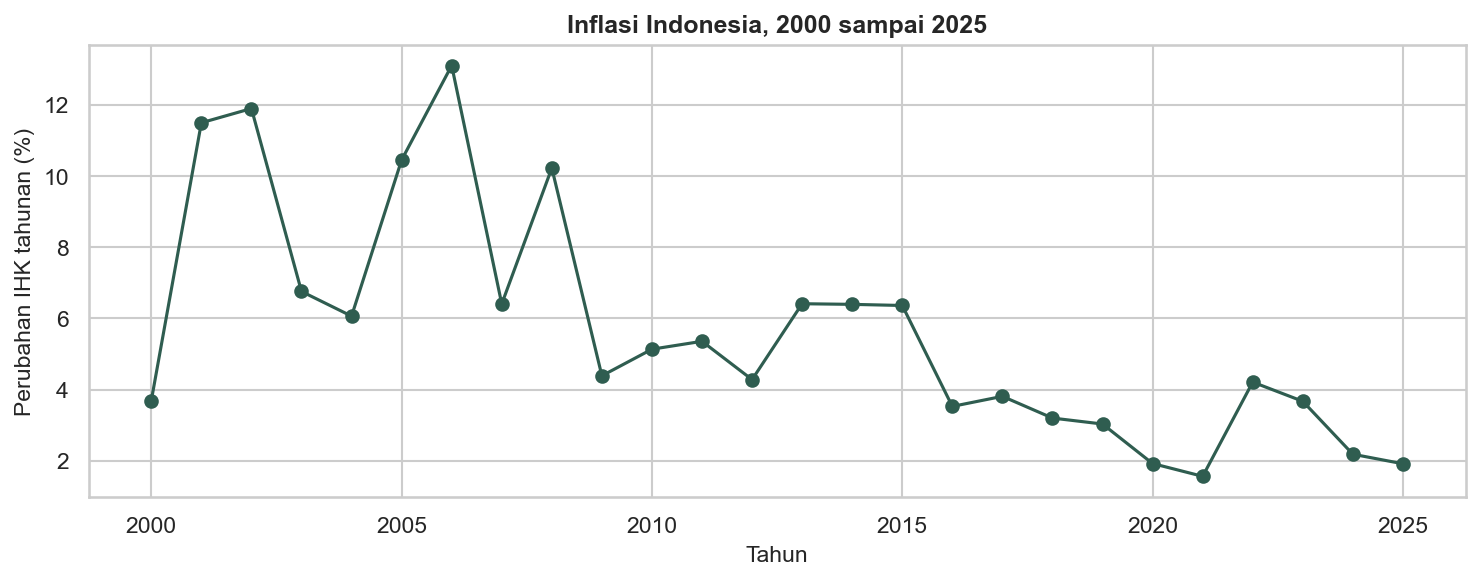

In [9]:
makro_spss.plot(x="tahun", y="Inflasi", marker="o", color="#2F5D50",
                figsize=(10, 4), legend=False)
plt.title("Inflasi Indonesia, 2000 sampai 2025")
plt.xlabel("Tahun")
plt.ylabel("Perubahan IHK tahunan (%)")
plt.xticks([2000, 2005, 2010, 2015, 2020, 2025])
plt.tight_layout()
plt.show()

**Cara membaca:** satu titik menunjukkan inflasi Indonesia pada satu tahun.
Sumbu mendatar menunjukkan tahun; sumbu tegak menunjukkan perubahan tahunan
Indeks Harga Konsumen (IHK) dalam persen. Misalnya, nilai 5 berarti IHK naik
sekitar 5 persen dari tahun sebelumnya. Garis membantu melihat perubahan antarwaktu.
Grafik ini berasal dari berkas SPSS, tetapi isinya sama dengan tabel CSV sumber.
Ukuran inflasi tahunan World Bank ini jangan disamakan begitu saja dengan inflasi
bulanan atau angka Desember terhadap Desember.

Berkas sudah menjadi tabel pandas yang dapat diperiksa dan digambar.
Sekarang lanjutkan contoh regresi di bawah dengan data latihan yang telah disiapkan.

## 3. Baca data pertama

Satu baris perintah: `pd.read_csv(URL_DATA + "uts_2.csv")`. Fungsi `head()`
menampilkan 5 baris pertama supaya kita tahu isinya.



<!-- kamus_variabel:uts_2.csv -->

### Kenali data: Harga saham perusahaan

**Data:** `data/uts_2.csv`. **Satu baris:** satu perusahaan pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Y_Harga_Saham` | Harga satu lembar saham perusahaan. | Uang per lembar; skala mata uang tidak dirinci | Y: target |
| `X1_Pendapatan_per_Saham` | EPS (Earnings Per Share): laba per lembar saham; bukan total omzet perusahaan. | Uang per lembar; skala mata uang tidak dirinci | X: penjelas |
| `X2_Rasio_Utang_Ekuitas` | DER (Debt to Equity Ratio): total utang dibagi ekuitas perusahaan. | Rasio; 1,5 berarti utang 1,5 kali ekuitas (150%) | X: penjelas |
| `X3_Belanja_Iklan` | Jumlah pengeluaran perusahaan untuk iklan. | Uang; skala dan periode belanja tidak dirinci | X: penjelas |

Nama harga, eps, der, dan iklan adalah nama singkat dari kolom di atas. Contoh DER tidak dibaca sebagai 1,5 persen.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [10]:
saham = pd.read_csv(URL_DATA + "uts_2.csv")
saham.head()


,Y_Harga_Saham,X1_Pendapatan_per_Saham,X2_Rasio_Utang_Ekuitas,X3_Belanja_Iklan
0,255.2,15.5,1.2,55.1
1,180.9,8.2,2.1,30.8
2,350.1,25.1,0.8,80.5
3,410.5,30.8,0.5,95.2
4,155.3,6.5,2.4,25.3


## 4. Grafik pertama

Selalu lihat data sebelum menghitung. Kita pakai scatter plot sederhana.



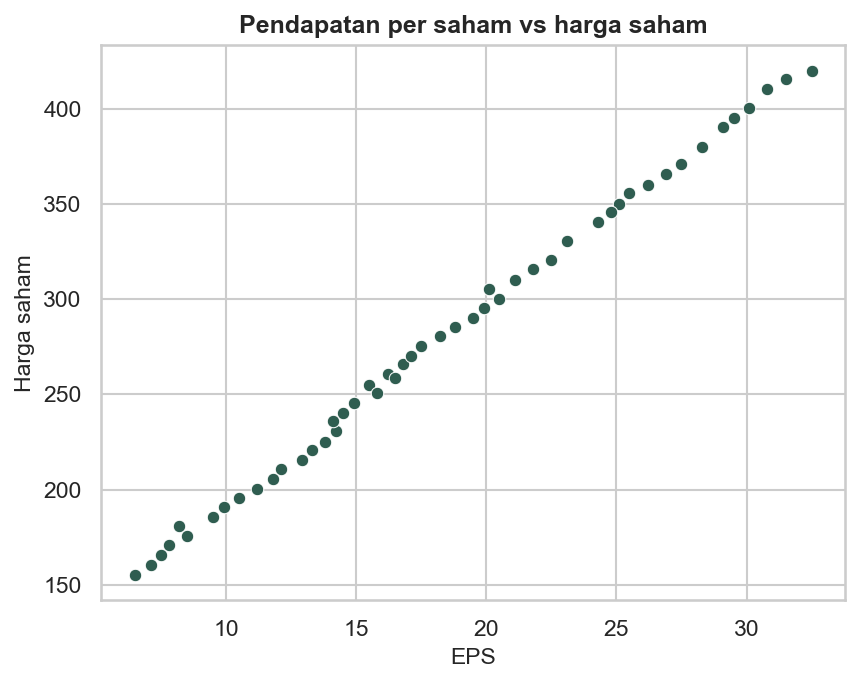

In [11]:
sns.scatterplot(data=saham, x="X1_Pendapatan_per_Saham", y="Y_Harga_Saham")
plt.title("Pendapatan per saham vs harga saham")
plt.xlabel("EPS")
plt.ylabel("Harga saham")
plt.show()


**Baca grafik sebelum lanjut:** Satu titik mewakili satu pengamatan. Baca nama dan satuan kedua sumbu, lalu jelaskan arah hubungan serta sebaran titik. Pola visual dipakai untuk memahami model berikutnya, bukan sebagai bukti kausal.

## 5. Regresi pertama

Rumus regresi ditulis `y ~ x`. Bagian kiri tilde adalah variabel yang
dijelaskan, bagian kanan adalah penjelasnya. `fit()` yang menaksir model.

Pertanyaan: apakah EPS berhubungan dengan harga saham?



In [12]:
sampel_model = saham[["Y_Harga_Saham", "X1_Pendapatan_per_Saham"]].dropna()
X_model = sampel_model[["X1_Pendapatan_per_Saham"]]
y_model = sampel_model["Y_Harga_Saham"]

model = LinearRegression()
model.fit(X_model, y_model)

koefisien_model = pd.Series(model.coef_, index=X_model.columns)
koefisien_model.loc["Intercept"] = model.intercept_


### Lihat hasil model: Harga saham (skala data)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

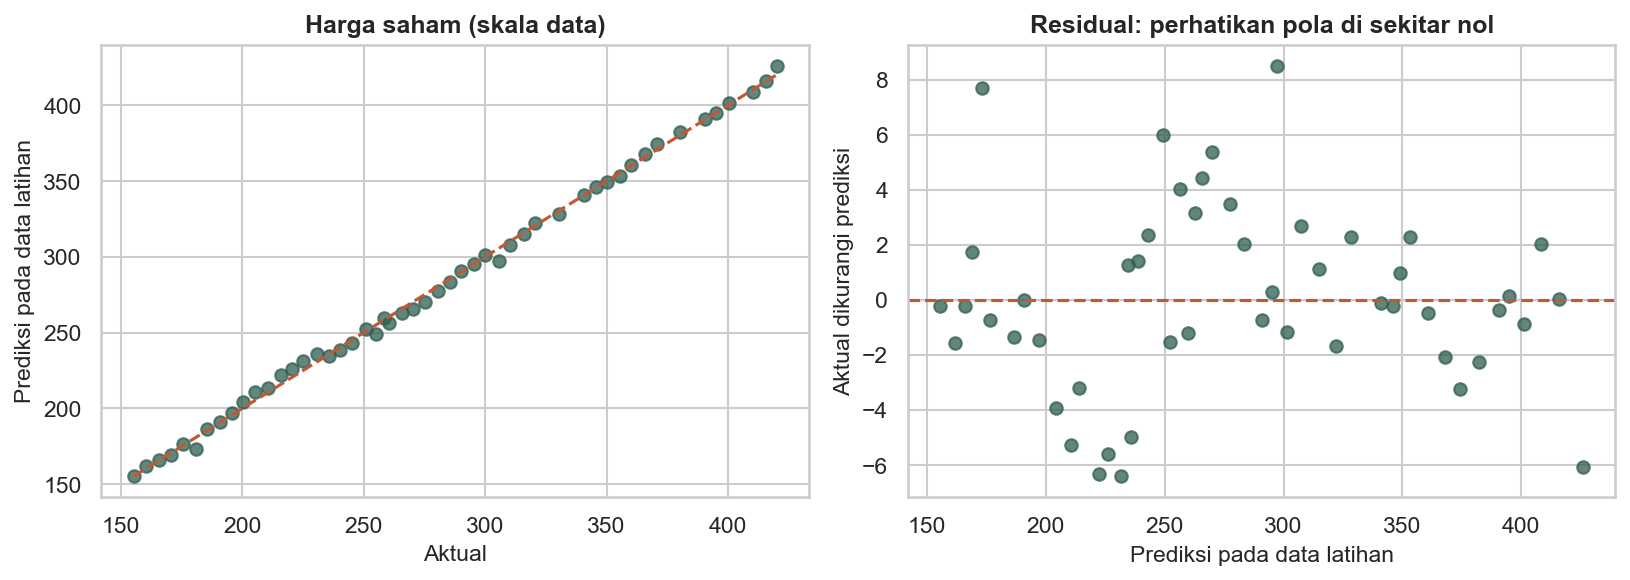

In [13]:
prediksi_visual = model.predict(X_model)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model.min(), y_model.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Harga saham (skala data)")
axes[1].scatter(prediksi_visual, y_model - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [14]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model = sm.OLS(
    y_model,
    sm.add_constant(X_model, has_constant="add").rename(columns={"const": "Intercept"}),
).fit()
print(uji_model.summary())


                            OLS Regression Results                            
Dep. Variable:          Y_Harga_Saham   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 2.487e+04
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           7.85e-67
Time:                        17:01:49   Log-Likelihood:                -131.31
No. Observations:                  50   AIC:                             266.6
Df Residuals:                      48   BIC:                             270.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

Tiga angka yang dibaca:

- `coef` baris pertama: intersep, nilai Y kalau X = 0.
- `coef` baris kedua: kemiringan, perubahan Y per satu unit X.
- `P>|t|` baris kedua: kalau di bawah 0,05, hubungannya signifikan.

**Cara membaca hasilnya:** kenaikan EPS satu unit diiringi kenaikan harga
saham sekitar 10,4 unit, dan hubungan itu signifikan (p-value jauh di
bawah 0,05).



In [15]:
print("Koefisien:")
print(koefisien_model.round(3))
print()
print("R-squared:", round(model.score(X_model, y_model), 3))


Koefisien:
X1_Pendapatan_per_Saham    10.410
Intercept                  87.847
dtype: float64

R-squared: 0.998


### Coba sendiri (5 menit)

Pakai `model` yang sudah jadi. Prediksi harga saham untuk EPS = 25.

Tulis di sel di bawah, baru buka jawabannya.



In [16]:
# Tulis kode Anda di sini


<details><summary>Lihat jawaban</summary>

`model.predict(pd.DataFrame({"X1_Pendapatan_per_Saham": [25]}))`
menghasilkan sekitar 348,1.

</details>



## 6. Latihan

1. Baca `data/uts_4.csv` ke variabel `harapan_hidup`. Tampilkan 5 baris
   pertama.
2. Hitung rata-rata kolom `Y_Angka_Harapan_Hidup` dan `X2_Tingkat_Imunisasi`
   dengan `.mean()`.
3. Jalankan regresi `Y_Angka_Harapan_Hidup ~ X1_Pengeluaran_Kesehatan`.
   Apakah koefisiennya signifikan?



<!-- kamus_variabel:uts_4.csv -->

### Kenali data: Angka harapan hidup

**Data:** `data/uts_4.csv`. **Satu baris:** satu negara pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Y_Angka_Harapan_Hidup` | Rata-rata lama hidup yang diharapkan menurut indikator pada contoh. | Tahun | Y: target |
| `X1_Pengeluaran_Kesehatan` | Pengeluaran kesehatan per penduduk (per kapita). | Uang per kapita; mata uang/periode tidak dirinci | X: penjelas |
| `X2_Tingkat_Imunisasi` | Persentase anak yang memperoleh imunisasi. | Persen; jenis imunisasi tidak dirinci | X: penjelas |
| `X3_Konsumsi_Kalori` | Rata-rata konsumsi energi makanan per hari. | Kalori harian; rincian satuan energi mengikuti sumber | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [17]:
# Tulis jawaban Anda di sini.
# harapan_hidup = pd.read_csv(...)
# harapan_hidup.head()
# ...


## Praktik pendampingan AI

Setelah contoh regresi berjalan, salin satu sel dan minta AI:

> Saya baru belajar coding. Jelaskan kode ini satu baris setiap kali
> dalam bahasa Indonesia. Sebutkan masukannya, hasil yang disimpan,
> serta bagian yang boleh saya ubah. Gunakan nama yang sama dan
> jangan menambahkan fungsi buatan sendiri atau perulangan.

Cocokkan penjelasannya dengan tabel data dan hasil kode yang dijalankan.
AI tidak perlu menebak koefisien. Ganti satu nilai prediksi, jalankan ulang,
lalu tulis kesimpulan sendiri dengan satuan yang benar. Contoh prompt
untuk membaca output dan memahami error ada di pengajar/README.md#pendampingan-ai.



### Selanjutnya

Selanjutnya: Lab 1, regresi linear lengkap.
